In [ ]:
!pip install qiskit qiskit-aer matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 63.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 96.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 85.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]


In [ ]:
# 4. Implement Quantum Teleportation algorithm in Python


Original Quantum Circuit:
     ┌───┐          ┌─┐      
q_0: ┤ H ├──■────■──┤M├──────
     └───┘┌─┴─┐  │  └╥┘┌─┐   
q_1: ─────┤ X ├──■───╫─┤M├───
          └───┘┌─┴─┐ ║ └╥┘┌─┐
q_2: ──────────┤ X ├─╫──╫─┤M├
               └───┘ ║  ║ └╥┘
c: 3/════════════════╩══╩══╩═
                     0  1  2 

Original Measurement Counts:
{'110': 414, '001': 281, '101': 405, '011': 412, '111': 3694, '100': 265, '010': 251, '000': 4278}

Mitigated Measurement Counts:
{'000': 4937, '001': 26, '010': 0, '011': 0, '100': 3, '101': 0, '110': 0, '111': 5035}


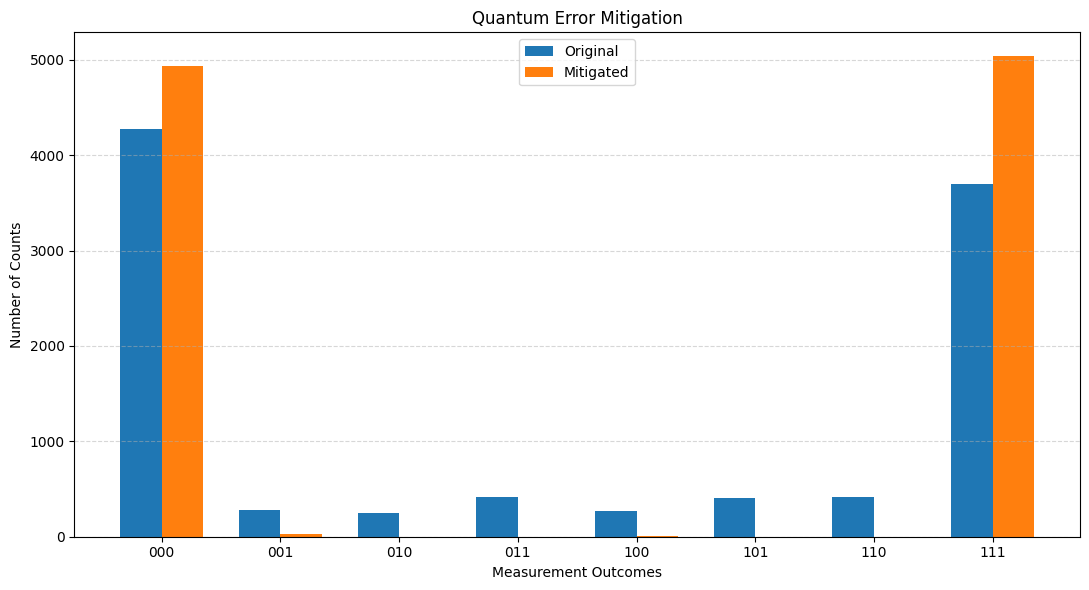

In [ ]:
# Practical 4: Tackle Noise with Error Correction

# Step 1: Import required libraries
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError
import numpy as np
import matplotlib.pyplot as plt

# Step 2: Create a quantum circuit
qc = QuantumCircuit(3, 3)

# Step 3: Apply gates to the circuit
qc.h(0)
qc.cx(0, 1)
qc.ccx(0, 1, 2)

# Step 4: Measure all qubits
qc.measure([0, 1, 2], [0, 1, 2])

print("\nOriginal Quantum Circuit:")
print(qc.draw())

# Step 5: Create a noise model
noise_model = NoiseModel()

# Define measurement errors
readout_error = ReadoutError([
    [0.95, 0.05],
    [0.10, 0.90]
])

# Apply readout error to all qubits
noise_model.add_all_qubit_readout_error(readout_error)

# Step 6: Initialize noisy simulator
simulator = AerSimulator(noise_model=noise_model)

# Step 7: Execute the original circuit
shots = 10000

compiled_qc = transpile(qc, simulator)
job = simulator.run(compiled_qc, shots=shots)

result = job.result()
counts = result.get_counts()

print("\nOriginal Measurement Counts:")
print(counts)

# Step 8: Generate calibration circuits
# There are 8 possible states for 3 qubits

states = [format(i, '03b') for i in range(8)]

calibration_matrix = np.zeros((8, 8))

for column, state in enumerate(states):

    cal_circuit = QuantumCircuit(3, 3)

    # Prepare the required basis state
    for qubit, bit in enumerate(reversed(state)):
        if bit == '1':
            cal_circuit.x(qubit)

    # Measure all qubits
    cal_circuit.measure([0, 1, 2], [0, 1, 2])

    # Execute calibration circuit
    compiled_cal = transpile(cal_circuit, simulator)

    cal_result = simulator.run(
        compiled_cal, shots=shots
    ).result()

    cal_counts = cal_result.get_counts()

    # Store probabilities in calibration matrix
    for row, measured_state in enumerate(states):
        calibration_matrix[row, column] = (
            cal_counts.get(measured_state, 0) / shots
        )

# print("\nCalibration Matrix:")
# print(np.round(calibration_matrix, 3))

# Step 9: Apply measurement error mitigation

# Convert original counts into a probability vector
measured_vector = np.array([
    counts.get(state, 0) / shots for state in states
])

# Apply inverse calibration matrix
corrected_vector = np.linalg.pinv(
    calibration_matrix
) @ measured_vector

# Remove negative probabilities
corrected_vector = np.clip(corrected_vector, 0, None)

# Normalize probabilities
corrected_vector = corrected_vector / corrected_vector.sum()

# Convert probabilities into corrected counts
mitigated_counts = {
    state: round(probability * shots)
    for state, probability in zip(states, corrected_vector)
}

print("\nMitigated Measurement Counts:")
print(mitigated_counts)

# Step 10: Plot original and mitigated results

x = np.arange(len(states))
width = 0.35

original_values = [
    counts.get(state, 0) for state in states
]

mitigated_values = [
    mitigated_counts[state] for state in states
]

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    original_values,
    width,
    label='Original'
)

plt.bar(
    x + width / 2,
    mitigated_values,
    width,
    label='Mitigated'
)

plt.xlabel('Measurement Outcomes')
plt.ylabel('Number of Counts')
plt.title('Quantum Error Mitigation')
plt.xticks(x, states)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
